In [36]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from scipy.stats import gaussian_kde
import scipy.stats as st

In [31]:
sns.set_style("whitegrid")

# 1. Variables in literature

# 2. Cyclists

The files cyclists-helsinki.csv and cyclists-espoo.csv contain daily numbers of cyclists spotted on
selected streets in Helsinki and Espoo.

* Load the files and merge the data into a single data frame.
* For how many days were observations made in total?
* How many observation days were there for each street?
* On how many days were all streets observed simultaneously?
* Which street was the busiest in terms of the total number of cyclists?
* Filter out the dates which have one or more missing values. Does this affect your conclusion about the
busiest street? Why or why not?

In [ ]:
helsinki_file_path = os.path.join("../data", "cyclists-helsinki.csv")
espoo_file_path = os.path.join("../data", "cyclists-espoo.csv")

print(os.path.exists(helsinki_file_path))
print(os.path.exists(espoo_file_path))

df_helsinki = pd.read_csv(helsinki_file_path)
df_espoo = pd.read_csv(espoo_file_path)





True
True


,date,Gallen-Kallela,Länsiväylä,Länsituulenkuja
0,2014-01-03,NaN,NaN,NaN
1,2014-01-04,NaN,NaN,NaN
2,2014-01-05,NaN,NaN,NaN
3,2014-01-06,NaN,NaN,NaN
4,2014-01-07,NaN,NaN,NaN


In [5]:
# Merge datasets on the shared 'date' column, keeping all dates
# Ensure 'date' is parsed as datetime in both dataframes
df_helsinki["date"] = pd.to_datetime(df_helsinki["date"], errors="coerce")
df_espoo["date"] = pd.to_datetime(df_espoo["date"], errors="coerce")

# Outer join to include every date present in either dataset
df_merged = (
    pd.merge(df_helsinki, df_espoo, on="date", how="outer")
      .sort_values("date")
      .reset_index(drop=True)
)

df_merged.head()


,date,Eteläesplanadi,Kaivokatu,Kuusisaarentie,Merikannontie,Gallen-Kallela,Länsiväylä,Länsituulenkuja
0,2014-01-01,129.0,NaN,NaN,NaN,NaN,NaN,NaN
1,2014-01-02,526.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2014-01-03,546.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2014-01-04,259.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2014-01-05,230.0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# For how many days were observations made in total?
print(df_merged["date"].nunique())


3134


In [12]:
# How many observation days were there for each street?
# Count non-missing values per street (each non-NaN = observed that day)
street_day_counts = (
    df_merged.drop(columns=["date"]).count().sort_values(ascending=False)
)
# Display as a DataFrame for readability
street_day_counts.rename("observation_days").to_frame()

,observation_days
Eteläesplanadi,3072
Merikannontie,2843
Kuusisaarentie,2640
Länsituulenkuja,2209
Kaivokatu,1722
Länsiväylä,1460
Gallen-Kallela,1459


In [22]:
# On how many days were all streets observed simultaneously?

mask = df_merged.notna().all(axis=1)      # or: ~df.isna().any(axis=1)
df_no_nulls = df_merged[mask]

df_no_nulls.shape

(1400, 8)

In [25]:
# Which street was the busiest in terms of the total number of cyclists?
# Sum totals per street across all days (ignore 'date')
street_totals = df_merged.drop(columns=["date"]).sum(numeric_only=True)

busiest_street = street_totals.idxmax()
busiest_total = street_totals.max()

print(f"Busiest street: {busiest_street} (total cyclists: {int(busiest_total)})")

# Show totals per street sorted descending for context
street_totals.sort_values(ascending=False).rename("total_cyclists").to_frame()



Busiest street: Merikannontie (total cyclists: 4839490)


,total_cyclists
Merikannontie,4839490.0
Eteläesplanadi,3677532.0
Kaivokatu,3675674.0
Kuusisaarentie,2823869.0
Länsituulenkuja,2037502.0
Länsiväylä,1324149.0
Gallen-Kallela,1107151.0


In [ ]:
# Filter out the dates which have one or more missing values. Does this affect your conclusion about the busiest street? Why or why not?

In [26]:
# Redo busiest-street analysis after filtering out dates with any missing values
# Keep only rows (dates) with complete observations across all columns
df_complete = df_merged.dropna()
print(f"Complete-case days: {len(df_complete)}")

# Totals per street on complete-case data
street_totals_complete = df_complete.drop(columns=["date"]).sum(numeric_only=True)

busiest_street_complete = street_totals_complete.idxmax()
busiest_total_complete = street_totals_complete.max()

print(f"Busiest street (complete-case): {busiest_street_complete} (total cyclists: {int(busiest_total_complete)})")

# Show totals per street (complete-case), sorted descending
street_totals_complete.sort_values(ascending=False).rename("total_cyclists_complete").to_frame()

# Compare with previous conclusion if available
try:
    changed = "changed" if busiest_street_complete != busiest_street else "unchanged"
    print(f"Conclusion {changed}: previously '{busiest_street}', now '{busiest_street_complete}'.")
except NameError:
    pass



Complete-case days: 1400
Busiest street (complete-case): Kaivokatu (total cyclists: 3016688)
Conclusion changed: previously 'Merikannontie', now 'Kaivokatu'.


# 3. Human Heights

* Create a histogram and a density plot of the following two sets of data points, which contain human heights measured in centimeters:
    * 170, 192, 184, 168, 176, 181, 163
    * 170, 170, 170, 170, 192, 192, 192, 192, 184, 184, 184, 184, 168, 168, 168, 168, 176, 176, 176, 176, 181, 181, 181, 181, 163, 163, 163, 163
* Based on the plots, would you consider the distributions to be normal? How confident are you about your conclusion?
* The data sets contain similar values, but your conclusions may differ. Can you explain such a difference in your results?
* (BONUS) Use a statistical test to assess the normality of the distributions. (NOTE: The test needed here will be introduced in the topic 4.)

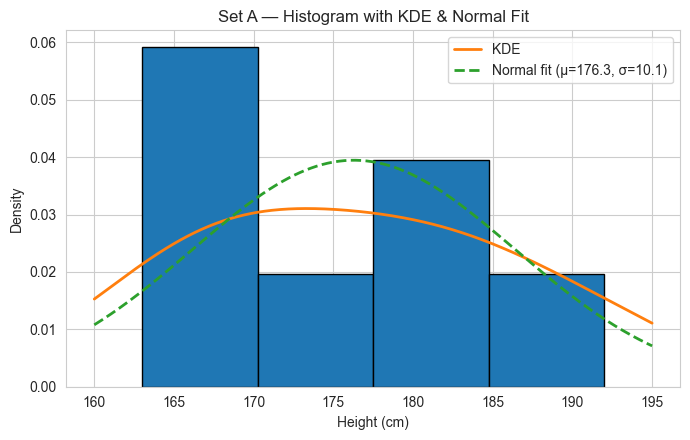

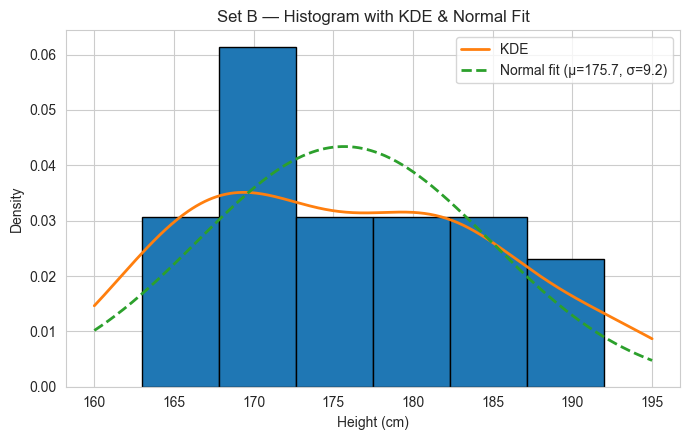

In [41]:
A = np.array([170, 192, 184, 168, 176, 181, 163])  # Set A (7 points)
B = np.array([
    170, 170, 170, 170,
    192, 192, 192, 184,
    184, 184, 184, 168,
    168, 168, 168, 175,
    176, 176, 176, 181,
    181, 181, 181, 163,
    163, 163, 163
])  # Set B (28 points)

def kde_smooth(x, grid=None, bandwidth=None):
    x = np.asarray(x, dtype=float)
    if grid is None:
        grid = np.linspace(x.min() - 3, x.max() + 3, 400)
    
    kde = gaussian_kde(x, bw_method=bandwidth)
    return grid, kde(grid)

def normal_pdf(grid, mu, sigma):
    sigma = float(sigma)
    if sigma <= 0 or not np.isfinite(sigma):
        sigma = 1e-6
    return (1 / (np.sqrt(2 * np.pi) * sigma)) * np.exp(-0.5 * ((grid - mu) / sigma) ** 2)

def plot_hist_kde_normal(data, title):
    data = np.asarray(data, dtype=float)

    plt.figure(figsize=(7, 4.5))
    # Histogram scaled as a density so curves are comparable
    plt.hist(data, bins="auto", density=True, edgecolor="black")

    # KDE line
    grid, dens = kde_smooth(data)
    plt.plot(grid, dens, linewidth=2, label="KDE")

    # Normal fit overlay
    mu, sigma = data.mean(), data.std(ddof=1)
    plt.plot(grid, normal_pdf(grid, mu, sigma), linestyle="--", linewidth=2,
             label=f"Normal fit (μ={mu:.1f}, σ={sigma:.1f})")

    plt.title(title)
    plt.xlabel("Height (cm)")
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()

# --- Make the charts ---
plot_hist_kde_normal(A, "Set A — Histogram with KDE & Normal Fit")
plot_hist_kde_normal(B, "Set B — Histogram with KDE & Normal Fit")
plt.show()

In [42]:
def describe(x):
    x = np.asarray(x, dtype=float)
    return {
        "n": x.size,
        "mean": float(np.mean(x)),
        "std": float(np.std(x, ddof=1)),
        "min": float(np.min(x)),
        "q25": float(np.quantile(x, 0.25)),
        "median": float(np.median(x)),
        "q75": float(np.quantile(x, 0.75)),
        "max": float(np.max(x)),
    }

def run_tests(x, label=""):
    print(f"\n=== {label} ===")
    d = describe(x)
    print(f"n={d['n']}, mean={d['mean']:.3f}, sd={d['std']:.3f}, "
          f"min={d['min']:.1f}, q25={d['q25']:.1f}, med={d['median']:.1f}, "
          f"q75={d['q75']:.1f}, max={d['max']:.1f}")


    # Shapiro–Wilk
    W, p_shapiro = st.shapiro(x)
    print(f"Shapiro–Wilk:     W={W:.5f}, p={p_shapiro:.5f}")

    # Anderson–Darling for normal
    ad = st.anderson(x, dist="norm")
    # report the 5% critical value (index 2 in SciPy's output)
    print(f"Anderson–Darling: A^2={ad.statistic:.5f}, "
          f"5% critical={ad.critical_values[2]:.3f}")


# --- Run on both sets ---
run_tests(A, "Set A")
run_tests(B, "Set B")



=== Set A ===
n=7, mean=176.286, sd=10.111, min=163.0, q25=169.0, med=176.0, q75=182.5, max=192.0
Shapiro–Wilk:     W=0.97619, p=0.93907
Anderson–Darling: A^2=0.15612, 5% critical=0.742

=== Set B ===
n=27, mean=175.667, sd=9.194, min=163.0, q25=168.0, med=176.0, q75=182.5, max=192.0
Shapiro–Wilk:     W=0.92452, p=0.05079
Anderson–Darling: A^2=0.65257, 5% critical=0.707


# 4. World temperature
* Download the data set from https://climate.nasa.gov/vital-signs/global-temperature/ and consider the No_smoothing variable.
* Calculate the mean and the median of the data
* Create a histogram and a density plot for the pre-2000 measurements. Does the variable seem to be normally distributed?
* Create a histogram and a density plot for the measurements from year 2000 onwards. Does the variable seem to be normally distributed?
* (BONUS) Use a statistical test to assess the normality of the distributions. (NOTE: The test needed here will be introduced in the topic 4.)

In [47]:
temp_file_path = os.path.join("../data", "land_ocean_temperature_index.csv")

print(os.path.exists(temp_file_path))

df_temp = pd.read_csv(temp_file_path)

print(df_temp["No_Smoothing"].mean())

print(df_temp["No_Smoothing"].median())




True
0.07296551724137933
-0.03


<Axes: >

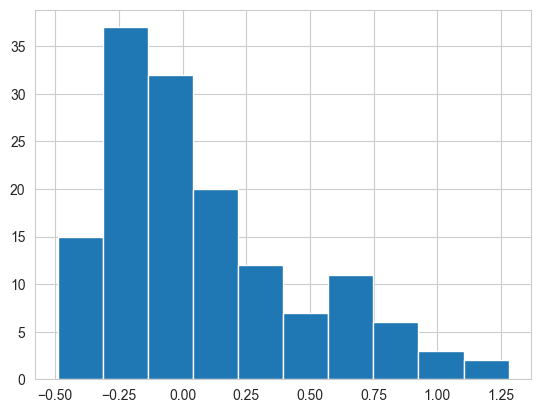

In [50]:
df_temp["No_Smoothing"].hist()



<Axes: ylabel='Density'>

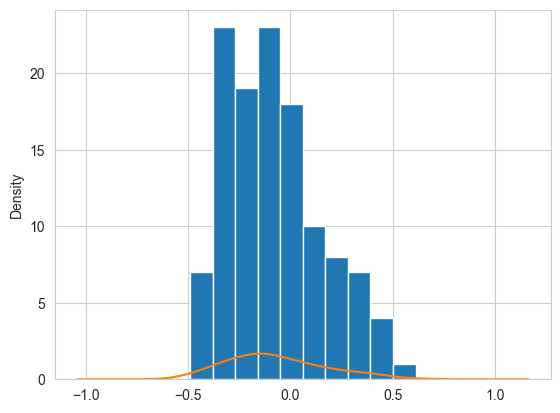

In [57]:
df_temp["No_Smoothing"][df_temp["Year"] < 2000].hist()

df_temp["No_Smoothing"][df_temp["Year"] < 2000].plot(kind="density")


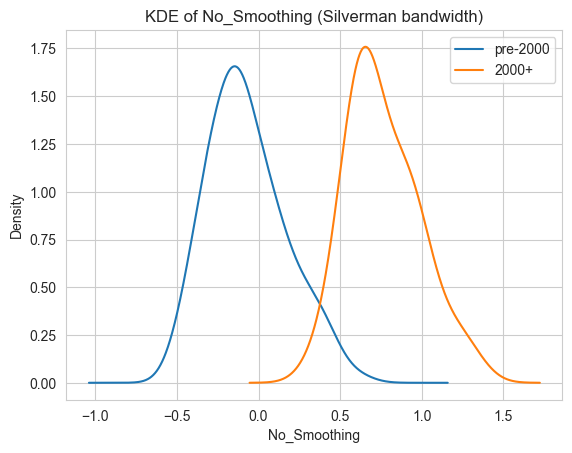

In [62]:
df_temp_pre_2000 = df_temp[df_temp["Year"] < 2000]
df_temp_2000 = df_temp[df_temp["Year"] >= 2000]

ax = df_temp_pre_2000["No_Smoothing"].plot(kind='density', bw_method='silverman', label='pre-2000')
df_temp_2000['No_Smoothing'].plot(kind='density', bw_method='silverman', ax=ax, label='2000+')
ax.set_xlabel('No_Smoothing')
ax.set_ylabel('Density')
ax.set_title('KDE of No_Smoothing (Silverman bandwidth)')
ax.legend()



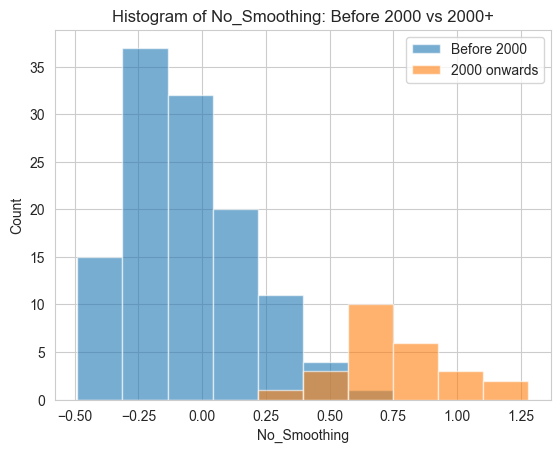

In [66]:
pre = df_temp_pre_2000["No_Smoothing"].to_numpy()
post = df_temp_2000["No_Smoothing"].to_numpy()

edges = np.histogram_bin_edges(np.concatenate([pre, post]), bins="auto")

plt.figure()
plt.hist(pre, bins=edges, alpha=0.6, label="Before 2000")  # counts by default
plt.hist(post, bins=edges, alpha=0.6, label="2000 onwards")
plt.xlabel("No_Smoothing")
plt.ylabel("Count")  # use plt.ylabel("Density") and density=True if you prefer normalized histograms
plt.title("Histogram of No_Smoothing: Before 2000 vs 2000+")
plt.legend()
plt.show()